# Riesgo de mora en crédito de consumo (Perú) — Segunda entrega
**Machine Learning I · Universidad Externado de Colombia · Profesora Juliana De Mier**

**Pregunta de investigación (reformulada como pregunta predictiva):**
¿Qué tan bien puede predecirse el riesgo de mora de un cliente de crédito de consumo a partir de información financiera y socioeconómica disponible previamente?

**Cómo leer este notebook.** Está organizado en el mismo orden que el informe. Cada decisión importante (qué significa `mora`, qué variables usar, si se imputa, si se balancea) tiene una celda de texto que explica *qué decidimos y por qué*, seguida de la celda de código que lo comprueba con los datos.

**Modelos (vistos en clase):** línea base (mayoría), **regresión logística** (principal, como en la 1.ª entrega y el artículo), **LDA** (prometido en la 1.ª entrega; sesión 34), **KNN** y **Naive Bayes** (contraste probabilístico, visto en agosto). Quedan fuera QDA, Ridge/Lasso y modelos fuera del curso (XGBoost, árboles, redes). Balanceo: peso de clases, sub/sobremuestreo y SMOTE.

**Cambios frente al plan de la primera entrega**

| Tema | Primera entrega | Ahora y por qué |
|---|---|---|
| Modelos | Regresión logística, Ridge/Lasso, LDA y KNN | Logística, **LDA**, KNN y Naive Bayes (NB como contraste, no principal). QDA/Ridge para la entrega final |
| Naive Bayes | Fuera de los modelos principales, por suponer independencia | Sigue sin ser modelo principal; entra solo como contraste porque ya lo vimos y mide el costo de ese supuesto |
| Balanceo | «Evaluar si conviene» | Se probaron cinco opciones; el AUC no mejora, así que se entrena sin balancear |
| Imputación | Mediana | Mediana más un indicador de faltante, porque faltar no es aleatorio |
| Variables | 13 predictores | Escenario principal de 11, sin `atraso` ni `clasif_sbs`, por riesgo de fuga |
| Métricas | AUC y Recall, con la meta «Precision > 70 %» | AUC principal; no hay metas fijas, se miran los tipos de error frente a la línea base |
| Pregunta | Qué características aumentan la probabilidad de mora | Qué tan bien puede predecirse el riesgo de mora |

**Índice**
1. Configuración y carga de datos
2. ¿Qué significa `mora`? (corrección 1)
3. Momento de predicción y auditoría de variables (correcciones 2 y 3)
4. Calidad de los datos: duplicados y faltantes
5. Partición entrenamiento / prueba
6. Línea base
7. Pipelines, modelos y supuestos
8. Pruebas de que no hay fuga de datos
9. Decisión sobre el balance de clases
10. Comparación de modelos con validación cruzada (ROC-AUC y PR-AUC)
11. Evaluación final en prueba + umbral OOF (Youden)
12. Análisis de sensibilidad: ¿qué pasa con y sin las variables sospechosas?
13. Interpretación del modelo (sin hablar de causas)
14. Conclusiones, limitaciones y lista de chequeo de la rúbrica


## 1. Configuración y carga de datos
Fijamos una semilla (`SEED = 42`) para que cualquiera que corra el notebook obtenga exactamente los mismos resultados. Los gráficos y tablas se guardan en la carpeta `salidas/` para usarlos en el informe.


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
# imblearn (pip install imbalanced-learn): permite balancear DENTRO del pipeline, solo con los datos de entrenamiento
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve, make_scorer)

# Algunas versiones de scikit-learn avisan que el parámetro 'penalty' cambiará de nombre.
# El aviso no afecta los resultados, así que lo silenciamos para que el notebook se lea limpio.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
os.makedirs("salidas", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
from pathlib import Path
_candidatos = [Path("../datos/database.csv"), Path("datos/database.csv"), Path("/content/database.csv")]
_data = next((p for p in _candidatos if p.exists()), None)
if _data is None:
    raise FileNotFoundError("Suba database.csv a datos/ o a /content en Colab")
df_raw = pd.read_csv(_data)
print("Filas y columnas:", df_raw.shape, "| archivo:", _data)
df_raw.head()


Filas y columnas: (8399, 14) | archivo: ..\datos\database.csv


,mora,atraso,vivienda,edad,dias_lab,exp_sf,nivel_ahorro,ingreso,linea_sf,deuda_sf,score,zona,clasif_sbs,nivel_educ
0,0,235,FAMILIAR,30,3748,93.0,5,3500.0,NaN,0.00,214,Lima,4,UNIVERSITARIA
1,0,18,FAMILIAR,32,4598,9.0,12,900.0,1824.67,1933.75,175,La Libertad,1,TECNICA
2,0,0,FAMILIAR,26,5148,8.0,2,2400.0,2797.38,188.29,187,Lima,0,UNIVERSITARIA
3,0,0,FAMILIAR,36,5179,20.0,12,2700.0,NaN,0.00,187,Ancash,0,TECNICA
4,0,0,FAMILIAR,46,3960,NaN,1,3100.0,2000.00,11010.65,189,Lima,0,TECNICA


In [3]:
# Tipos de variables
print(df_raw.dtypes)
print()
print("Proporción de mora en la base original:", round(df_raw["mora"].mean(), 3))


mora              int64
atraso            int64
vivienda         object
edad              int64
dias_lab          int64
exp_sf          float64
nivel_ahorro      int64
ingreso         float64
linea_sf        float64
deuda_sf        float64
score             int64
zona             object
clasif_sbs        int64
nivel_educ       object
dtype: object

Proporción de mora en la base original: 0.704


## 2. ¿Qué significa `mora`? (corrección 1)

**Lo que dice la fuente.** La base se llama *BankDefaultAnalysis / Morosidad del Sistema Financiero* (Calderón Baldeón, 2021). La descripción del autor en Kaggle habla de varios elementos: el *score* de calificación crediticia, el *nivel de ahorro* (de 0 a 12), el *atraso histórico* (en número de días), la *calificación absoluta del cliente* como «pagador al día» o «cliente moroso» y la clasificación de riesgo de la SBS (de 0 «normal» a 4 «pérdida»). **No hay un diccionario de datos** que diga con qué umbral de días ni en qué periodo se construyó `mora`.

**Lo que podemos comprobar con los datos.** Si `mora` fuera «tiene atraso hoy», entonces `mora = 1` debería coincidir con `atraso > 0`. Lo revisamos abajo.

**Definición operativa que adoptamos** (y que declaramos como supuesto del trabajo):
> `mora = 1` indica que el cliente aparece marcado como **cliente moroso** en la base; `mora = 0` indica que aparece como **pagador al día**. Es una etiqueta de estado del cliente, no es lo mismo que tener atraso en el momento actual ni es un conteo de días.

Es decir, no la tratamos como «mora actual» ni como «mora en un periodo exacto»: la fuente no permite afirmarlo. Esto se menciona como limitación en el informe.


In [4]:
# Si mora fuera "tiene atraso hoy", esta tabla tendría ceros fuera de la diagonal.
tabla = pd.crosstab(df_raw["atraso"] > 0, df_raw["mora"], margins=True)
tabla.index = ["atraso = 0", "atraso > 0", "Total"]
tabla.columns = ["mora = 0", "mora = 1", "Total"]
display(tabla)

print("De los clientes con mora = 1, el", round(100 * (df_raw.loc[df_raw.mora == 1, "atraso"] == 0).mean(), 1),
      "% tiene atraso = 0.")
print("De los clientes con mora = 0, el", round(100 * (df_raw.loc[df_raw.mora == 0, "atraso"] > 0).mean(), 1),
      "% tiene atraso > 0.")


,mora = 0,mora = 1,Total
atraso = 0,1809,3415,5224
atraso > 0,675,2500,3175
Total,2484,5915,8399


De los clientes con mora = 1, el 57.7 % tiene atraso = 0.
De los clientes con mora = 0, el 27.2 % tiene atraso > 0.


**Lectura.** Más de la mitad de los clientes con `mora = 1` tiene `atraso = 0`, y una parte de los clientes con `mora = 0` sí tiene días de atraso. Entonces `mora` **no es** «atraso mayor que cero». Es una etiqueta distinta, y por eso nuestra definición operativa habla de «cliente marcado como moroso» y no de «cliente con atraso hoy».


## 3. Momento de predicción y auditoría de variables (correcciones 2 y 3)

**Momento de predicción.** El modelo se pensó para el momento en que el banco evalúa a un cliente de crédito de consumo y necesita estimar su riesgo. En ese momento el banco conoce: sus datos personales y socioeconómicos, su historial en el sistema financiero y su score. **No conoce todavía** si el cliente va a quedar o no marcado como moroso. Por eso una variable solo es válida como predictor si existe *antes* de que se conozca la etiqueta `mora`.

**Auditoría de cada predictor.** Para cada variable respondemos cuatro preguntas: qué mide, cuándo se observa, si estaría disponible antes de saber la mora, y si la mora (o algo equivalente) pudo haberse usado para construirla. Como la base no trae diccionario, las respuestas sobre el momento de observación son **supuestos razonables** a partir de la descripción del autor, y los contrastamos con los datos cuando se puede.

| Variable | Qué mide | ¿Disponible antes de saber la mora? | ¿Pudo construirse con la mora? | Decisión |
|---|---|---|---|---|
| `edad`, `nivel_educ`, `vivienda`, `zona`, `dias_lab`, `ingreso`, `nivel_ahorro` | Perfil personal, laboral y económico | Sí, se conocen al evaluar el crédito | No | Se usan |
| `exp_sf`, `linea_sf`, `deuda_sf` | Experiencia, línea de crédito y deuda en el sistema financiero | Sí, si corresponden a la fecha de evaluación; la fuente no lo garantiza | No directamente | Se usan, con la salvedad anterior |
| `score` | Calificación crediticia; mayor score = mejor perfil | Normalmente sí, es una herramienta de evaluación; pero un score actualizado después de un atraso sí incorporaría la mora | Posible | **Sospechosa leve**: se usa en el escenario principal y se evalúa quitándola |
| `atraso` | Días de atraso histórico | Depende del periodo que cubra; si incluye atrasos recientes, mide casi lo mismo que la mora | Posible | **Sospechosa**: se excluye del escenario principal |
| `clasif_sbs` | Clasificación de riesgo del crédito de la SBS (0 normal … 4 pérdida), que se asigna según el comportamiento de pago | No: se asigna observando si el cliente ya pagó o no | Muy posible | **Sospechosa**: se excluye del escenario principal |

Una relación muy directa entre una variable y `mora` es una señal de alerta. Revisamos qué tan directa es en estas tres variables.


In [5]:
df = df_raw.drop_duplicates().reset_index(drop=True)   # se explica en la sección 4
sus = ["atraso", "clasif_sbs", "score"]

# Correlación de Spearman con mora (sirve para variables ordenadas, no supone relación lineal)
corr = df[sus + ["mora"]].corr(method="spearman")["mora"].drop("mora").round(3)
print("Correlación de Spearman con mora:")
print(corr.to_string())


Correlación de Spearman con mora:
atraso        0.147
clasif_sbs    0.086
score        -0.220


In [6]:
# ¿La clasificación SBS 'pérdida' (4) implica mora? Si hubiera fuga directa, el porcentaje sería ~100%.
t = df.groupby("clasif_sbs")["mora"].agg(["mean", "size"]).rename(columns={"mean": "% con mora", "size": "clientes"})
t["% con mora"] = (100 * t["% con mora"]).round(1)
display(t)

# ¿Y el atraso? Mora por tramos de días de atraso
tramos = pd.cut(df["atraso"], [-1, 0, 8, 30, 300], labels=["0", "1-8", "9-30", "más de 30"])
t2 = df.groupby(tramos, observed=True)["mora"].agg(["mean", "size"]).rename(columns={"mean": "% con mora", "size": "clientes"})
t2["% con mora"] = (100 * t2["% con mora"]).round(1)
display(t2)


,% con mora,clientes
clasif_sbs,,
0,68.2,3875
1,74.7,1477
2,78.3,447
3,79.0,124
4,79.5,151


,% con mora,clientes
atraso,,
0,65.8,3727
1-8,78.3,1553
9-30,81.4,644
más de 30,81.3,150


**Lectura de la auditoría.**
- **Criterio principal (feedback de la profesora):** excluimos `atraso` y `clasif_sbs` del escenario principal porque describen comportamiento de pago y no podemos asegurar, sin diccionario, que se observen *antes* de conocer la etiqueta `mora`. Eso es una decisión por **momento y definición**, no porque «correlacionen poco».
- **Complemento en los datos:** las correlaciones con `mora` son bajas o moderadas y, incluso en la clasificación SBS «pérdida», no todos tienen `mora = 1`. Eso no prueba que sea seguro usarlas; solo indica que no hay una copia exacta de la etiqueta.
- Por prudencia medimos **cuánto cambia el resultado** al incluirlas (sección 12).
- `score` es la variable que más se relaciona con `mora` y es normal que lo haga: es una medida de riesgo. La dejamos en el escenario principal, pero también probamos un escenario sin ella.


In [7]:
# Escenarios de variables que vamos a comparar
num_all = ["edad", "dias_lab", "exp_sf", "nivel_ahorro", "ingreso", "linea_sf", "deuda_sf", "score", "atraso", "clasif_sbs"]
cat_all = ["vivienda", "zona", "nivel_educ"]

ESCENARIOS = {
    "A. Completo (13 variables)":                       [c for c in num_all + cat_all],
    "B. Principal (sin atraso ni clasif_sbs)":          [c for c in num_all + cat_all if c not in ("atraso", "clasif_sbs")],
    "C. Conservador (sin atraso, clasif_sbs ni score)": [c for c in num_all + cat_all if c not in ("atraso", "clasif_sbs", "score")],
}
for k, v in ESCENARIOS.items():
    print(k, "->", len(v), "variables")
ESC_PRINCIPAL = "B. Principal (sin atraso ni clasif_sbs)"


A. Completo (13 variables) -> 13 variables
B. Principal (sin atraso ni clasif_sbs) -> 11 variables
C. Conservador (sin atraso, clasif_sbs ni score) -> 10 variables


## 4. Calidad de los datos: duplicados y faltantes

### 4.1 Duplicados
Hay filas completamente repetidas. Antes de decidir qué hacer, revisamos qué tipo de filas son.


In [8]:
n_dup = df_raw.duplicated().sum()
print("Filas repetidas:", n_dup, "de", len(df_raw), f"({100*n_dup/len(df_raw):.1f}%)")
print("Filas únicas:", len(df))

cols_fin = ["exp_sf", "linea_sf", "deuda_sf"]
dup_mask = df_raw.duplicated(keep="first")
print()
print("% de filas con algún dato financiero faltante")
print("  - entre las filas repetidas:", round(100 * df_raw[dup_mask][cols_fin].isna().any(axis=1).mean(), 1))
print("  - entre las filas únicas   :", round(100 * df_raw[~dup_mask][cols_fin].isna().any(axis=1).mean(), 1))
print()
print("Proporción de mora: base original =", round(df_raw.mora.mean(), 3), "| sin duplicados =", round(df.mora.mean(), 3))


Filas repetidas: 2325 de 8399 (27.7%)
Filas únicas: 6074

% de filas con algún dato financiero faltante
  - entre las filas repetidas: 1.3
  - entre las filas únicas   : 37.4

Proporción de mora: base original = 0.704 | sin duplicados = 0.71


**Decisión: eliminar los duplicados antes de dividir los datos.**
Las filas repetidas casi nunca tienen datos faltantes, mientras que entre las filas únicas más de un tercio sí los tiene. Esto sugiere que son copias de registros completos, y no coincidencias entre clientes distintos (con ingreso, deuda y línea de crédito iguales al centavo es muy poco probable que dos personas coincidan por azar). Lo cierto es que **no podemos comprobar** si son el mismo cliente, porque la base no tiene identificador. La decisión es conservadora: si dejamos las copias, la misma fila puede caer en entrenamiento y en prueba, y el modelo parecería mejor de lo que es. En la sección 12 mostramos cuánto se infla el resultado si no se eliminan.

### 4.2 Datos faltantes


In [9]:
faltantes = df[cols_fin].isna().mean().mul(100).round(1).rename("% faltante")
display(faltantes.to_frame())

# ¿Faltar es informativo? Miramos la proporción de mora según si el dato falta o no.
filas = []
for c in cols_fin:
    g = df.groupby(df[c].isna())["mora"].mean().mul(100).round(1)
    filas.append({"variable": c, "% mora si el dato existe": g[False], "% mora si el dato falta": g[True]})
display(pd.DataFrame(filas).set_index("variable"))


,% faltante
exp_sf,29.7
linea_sf,18.3
deuda_sf,7.4


,% mora si el dato existe,% mora si el dato falta
variable,,
exp_sf,67.3,79.7
linea_sf,69.4,78.3
deuda_sf,71.8,60.5


**Decisión sobre faltantes: sí se imputan, con la mediana, y además se marca cuáles eran faltantes.**
- Faltan datos solo en `exp_sf`, `linea_sf` y `deuda_sf`. Se imputan con la **mediana** (igual que en el artículo), porque las tres variables son muy asimétricas y la mediana no se ve afectada por valores extremos.
- La tabla muestra que **faltar no es aleatorio**: por ejemplo, los clientes sin `exp_sf` tienen más mora que los que sí lo reportan. Si solo imputáramos, perderíamos esa información. Por eso el imputador agrega una columna de «este dato faltaba» (indicador de faltante) por cada variable con faltantes.
- La mediana se calcula **solo con los datos de entrenamiento** dentro del pipeline (sección 7), para que la prueba no influya en el entrenamiento.
- No eliminamos filas con faltantes: perderíamos más del 37 % de los clientes únicos.


## 5. Partición entrenamiento / prueba
80 % entrenamiento y 20 % prueba, **estratificada** por `mora` para que ambos grupos tengan la misma proporción de morosos. Se hace después de eliminar duplicados. El conjunto de prueba **no se toca** hasta la sección 11.


In [10]:
X_full = df.drop(columns="mora")
y = df["mora"]

X_tr_full, X_te_full, y_tr, y_te = train_test_split(
    X_full, y, test_size=0.20, stratify=y, random_state=SEED)

print("Entrenamiento:", X_tr_full.shape, "| % mora =", round(100 * y_tr.mean(), 1))
print("Prueba       :", X_te_full.shape, "| % mora =", round(100 * y_te.mean(), 1))


Entrenamiento: (4859, 13) | % mora = 71.0
Prueba       : (1215, 13) | % mora = 71.0


## 6. Línea base (corrección 6)
La línea base es una estrategia «trivial»: predecir siempre la clase mayoritaria (`mora = 1`). No aprende nada, pero nos dice qué tan fácil es sacar buenos números en esta base. Con un 71 % de morosos, esta estrategia acierta mucho, tiene Recall de 100 % y una Precision cercana a 71 %, y sin embargo su AUC es 0.5. Por eso **ningún modelo se juzga con una regla fija como «Precision > 70 %»**: ese número depende de cuántos morosos hay en la muestra, no de qué tan bueno es el modelo. Cada modelo se compara contra esta línea base mirando juntos el AUC y los **tipos de error** que comete.


In [11]:
def evaluar(y_true, proba, pred):
    """Devuelve las métricas de un modelo. 'proba' = probabilidad de mora; 'pred' = clase predicha."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Recall (mora=1)": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "Precision (mora=1)": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "F1 (mora=1)": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "Recall (mora=0)": recall_score(y_true, pred, pos_label=0, zero_division=0),
        "Accuracy": accuracy_score(y_true, pred),
        "VP": tp, "FN": fn, "FP": fp, "VN": tn,
    }

base = DummyClassifier(strategy="most_frequent").fit(X_tr_full, y_tr)
p_base = base.predict_proba(X_te_full)[:, 1]
res_base = evaluar(y_te, p_base, base.predict(X_te_full))
pd.Series(res_base).to_frame("Línea base (siempre mora=1)").round(3)


,Línea base (siempre mora=1)
AUC,0.500
PR-AUC,0.710
Recall (mora=1),1.000
Precision (mora=1),0.710
F1 (mora=1),0.831
Recall (mora=0),0.000
Accuracy,0.710
VP,863.000
FN,0.000
FP,352.000


**Lectura.** La línea base no deja pasar a ningún buen pagador por error de «no detectar mora» (FN = 0), pero rechaza a **todos** los pagadores al día (VN = 0). Es un clasificador inútil en la práctica aunque su Recall y su Precision se vean altos. Un modelo útil debe **subir el AUC por encima de 0.5** y a la vez **reconocer a una parte de los buenos pagadores** sin perder demasiados morosos.


## 7. Pipelines, modelos y supuestos
Para evitar fuga de datos todo el preprocesamiento va **dentro de un `Pipeline`**. Así, en cada partición de la validación cruzada, la mediana, la media y la desviación estándar y las categorías del *one-hot* se calculan solo con los datos de entrenamiento de esa partición. Si más adelante se balancean las clases, también se hace dentro del pipeline (con `imblearn`), de modo que **solo se remuestrea el entrenamiento** y nunca los datos de validación ni de prueba.

**Orden de las etapas dentro del pipeline:**
1. Imputar faltantes con la mediana (y marcar cuáles faltaban).
2. Estandarizar las variables numéricas (importante para KNN).
3. Codificar las variables categóricas con one-hot.
4. (Opcional) Balancear las clases, solo con datos de entrenamiento.
5. Entrenar el modelo.

**Modelos (todos vistos en clase):**

| Modelo | Para qué lo usamos | Hiperparámetro |
|---|---|---|
| Regresión logística | Modelo principal; permite leer odds ratio | ninguno (sin penalización) |
| LDA | Comparador prometido en la 1.ª entrega; frontera lineal entre clases | ninguno |
| KNN | Comparar contra un modelo sin forma fija, que busca clientes parecidos | `k`, elegido con validación cruzada |
| Naive Bayes gaussiano | Modelo de contraste (no principal): mide el costo de suponer independencia | ninguno |

En la primera entrega dejamos Naive Bayes fuera de los modelos principales porque supone que las variables son independientes entre sí, y las nuestras no lo son del todo: hay relaciones moderadas entre las variables financieras (la revisión de abajo muestra, por ejemplo, correlaciones de Spearman cercanas a 0.55 entre `ingreso` y `score`, y entre `exp_sf` y `linea_sf`). **Esa razón sigue siendo válida**, por eso Naive Bayes **no es el modelo principal**. Lo incluimos solo como **modelo de contraste**, porque ya lo vimos en clase y porque nos sirve para medir cuánto cuesta suponer independencia: si la relación entre variables importa, suele quedar por debajo de logística, LDA y KNN. QDA y Ridge/Lasso quedan para la entrega final.

**Detalle del one-hot:** `drop="first"` elimina una categoría de referencia por variable (evita que las columnas sumen siempre 1, lo que haría inestables los coeficientes de la regresión logística) y `min_frequency=50` agrupa en una categoría «poco frecuente» las zonas con menos de 50 clientes.


In [12]:
def construir_pipeline(cols, modelo, muestreo=None):
    """Pipeline completo: preprocesamiento -> (balanceo opcional) -> modelo."""
    num = [c for c in cols if c in num_all]
    cat = [c for c in cols if c in cat_all]
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("esc", StandardScaler())]), num),
        ("cat", OneHotEncoder(drop="first", min_frequency=50, handle_unknown="infrequent_if_exist",
                              sparse_output=False), cat),
    ])
    pasos = [("prep", prep)]
    if muestreo is not None:
        pasos.append(("muestreo", muestreo))     # solo actúa cuando se llama a fit (entrenamiento)
    pasos.append(("modelo", modelo))
    return ImbPipeline(pasos)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # 5 grupos estratificados
K_LISTA = [5, 11, 21, 31, 51, 101, 151, 201]
NOMBRES_MOD = ["Regresión logística", "LDA", "KNN", "Naive Bayes"]

def ajustar_todos(cols, verbose=True):
    """Elige k de KNN con CV y ajusta los cuatro modelos en entrenamiento."""
    # 1) Elegir k de KNN: se prueba cada k con validación cruzada y se queda el de mayor AUC medio
    auc_k = {k: cross_val_score(construir_pipeline(cols, KNeighborsClassifier(k)),
                                X_tr_full[cols], y_tr, cv=cv, scoring="roc_auc") for k in K_LISTA}
    k_mejor = max(auc_k, key=lambda k: auc_k[k].mean())
    modelos = {
        "Regresión logística": LogisticRegression(C=1e6, max_iter=5000),
        "LDA": LinearDiscriminantAnalysis(),
        "KNN": KNeighborsClassifier(k_mejor),
        "Naive Bayes": GaussianNB(),
    }
    scoring_cv = {"roc": "roc_auc", "pr": "average_precision"}
    out = {}
    for nombre, m in modelos.items():
        pipe = construir_pipeline(cols, m)
        r = cross_validate(pipe, X_tr_full[cols], y_tr, cv=cv, scoring=scoring_cv)
        pipe.fit(X_tr_full[cols], y_tr)
        out[nombre] = {
            "modelo": pipe, "cv_media": r["test_roc"].mean(), "cv_std": r["test_roc"].std(),
            "pr_cv_media": r["test_pr"].mean(), "pr_cv_std": r["test_pr"].std(),
            "params": {"k": k_mejor} if nombre == "KNN" else {},
        }
        if verbose:
            print(f"{nombre:22s} ROC-AUC CV = {r['test_roc'].mean():.4f} ± {r['test_roc'].std():.4f} | "
                  f"PR-AUC CV = {r['test_pr'].mean():.4f} {out[nombre]['params']}")
    out["_auc_k"] = auc_k
    return out


### Revisión de variables parecidas y supuestos de la regresión logística
En la primera entrega dijimos que revisaríamos si `linea_sf`, `deuda_sf` e `ingreso` aportan casi la misma información. Lo comprobamos con la correlación entre variables y con el VIF (cuánto se explica cada variable con las demás; valores sobre 5 a 10 indican problema).


In [13]:
from sklearn.linear_model import LinearRegression
num_chk = ["edad", "dias_lab", "exp_sf", "nivel_ahorro", "ingreso", "linea_sf", "deuda_sf", "score"]
imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_tr_full[num_chk]), columns=num_chk)
imp = (imp - imp.mean()) / imp.std()
vif = {c: 1 / (1 - LinearRegression().fit(imp.drop(columns=c), imp[c]).score(imp.drop(columns=c), imp[c])) for c in num_chk}
vif = pd.Series(vif).round(2).rename("VIF")
vif.to_csv("salidas/tabla_vif.csv")
display(vif.to_frame().T)
corr_m = X_tr_full[num_chk].corr(method="spearman")
pares = corr_m.abs().where(np.triu(np.ones(corr_m.shape, dtype=bool), 1)).stack().dropna().sort_values(ascending=False)
print("Pares de variables numéricas:", len(pares))
print("  con correlación de Spearman >= 0.5:", int((pares >= 0.5).sum()))
print("  con correlación de Spearman >= 0.3:", int((pares >= 0.3).sum()))
print("Los tres pares más correlacionados:")
display(pares.head(3).round(2).to_frame("correlación"))


,edad,dias_lab,exp_sf,nivel_ahorro,ingreso,linea_sf,deuda_sf,score
VIF,1.52,1.35,1.46,1.05,1.51,1.59,1.14,1.44


Pares de variables numéricas:

 28
  con correlación de Spearman >= 0.5: 2
  con correlación de Spearman >= 0.3: 11
Los tres pares más correlacionados:


,,correlación
ingreso,score,0.55
exp_sf,linea_sf,0.54
ingreso,linea_sf,0.50


**Lectura.** Todos los VIF están por debajo de 2: no hay multicolinealidad fuerte, así que las variables de dinero (`ingreso`, `linea_sf`, `deuda_sf`) **no** repiten la misma información y la regresión logística puede estimar sus coeficientes sin problema. Pero «no hay multicolinealidad fuerte» no es lo mismo que «son independientes»: hay relaciones **moderadas** (ver los pares más correlacionados). Eso no molesta a la regresión logística, pero sí es una debilidad para Naive Bayes, cuyo supuesto de independencia no se cumple del todo. Por eso lo usamos solo como contraste.

**Tres tipos de supuestos que conviene no mezclar**

*1. Supuestos del modelo de regresión logística (propiedades que el modelo necesita):*
- La variable a predecir es binaria (`mora` es 0/1).
- Las observaciones son independientes entre sí (por eso se eliminan las copias exactas).
- Cada predictor numérico tiene una relación lineal con el **logit** (el logaritmo de la razón entre probabilidad de mora y de no mora), no con la probabilidad directamente. No lo verificamos variable por variable; una pista indirecta es que KNN, que no supone linealidad, no mejora a la regresión logística.
- No hay multicolinealidad fuerte (revisado arriba con VIF).
- Hay suficientes datos de cada clase para estimar los coeficientes.

*2. Decisiones de preprocesamiento (elecciones nuestras, no supuestos del modelo):*
- Imputar con la mediana y agregar indicador de faltante.
- Estandarizar las variables numéricas y codificar las categóricas con one-hot.
- Eliminar duplicados exactos antes de dividir.
- Excluir `atraso` y `clasif_sbs` del escenario principal.

*3. Supuestos sobre la calidad de los datos (el modelo no puede comprobarlos solo):*
- `mora` está bien medida y significa lo mismo para todos los clientes.
- Los valores faltantes son datos realmente desconocidos y no errores de captura.
- Las variables se midieron antes de conocerse la mora.
- La muestra se parece a la población sobre la que se quiere decidir. **Esto no se cumple del todo:** la base tiene 71 % de morosos y el sistema peruano entre 4 % y 11 %.


## 8. Pruebas de que no hay fuga de datos
No basta con decir que el pipeline evita la fuga: aquí lo **comprobamos** con cuatro pruebas. Todas se hacen sobre el escenario principal (B).


In [14]:
cols_P = ESCENARIOS[ESC_PRINCIPAL]

# Prueba 1: ninguna fila está a la vez en entrenamiento y en prueba
comunes = X_tr_full.merge(X_te_full, how="inner")
print("Prueba 1 - filas idénticas entre entrenamiento y prueba:", len(comunes), "(debe ser 0)")
assert len(comunes) == 0


Prueba 1 - filas idénticas entre entrenamiento y prueba: 0 (debe ser 0)


In [15]:
# Prueba 2: la estratificación se mantiene en la partición y en cada grupo de la validación cruzada
filas = [{"Conjunto": "Base completa (sin duplicados)", "Clientes": len(y), "% mora": 100 * y.mean()},
         {"Conjunto": "Entrenamiento", "Clientes": len(y_tr), "% mora": 100 * y_tr.mean()},
         {"Conjunto": "Prueba", "Clientes": len(y_te), "% mora": 100 * y_te.mean()}]
for i, (tr_idx, va_idx) in enumerate(cv.split(X_tr_full, y_tr), start=1):
    filas.append({"Conjunto": f"CV grupo {i} - validación", "Clientes": len(va_idx), "% mora": 100 * y_tr.iloc[va_idx].mean()})
t_estrat = pd.DataFrame(filas).set_index("Conjunto").round(1)
t_estrat.to_csv("salidas/tabla_estratificacion.csv")
display(t_estrat)


,Clientes,% mora
Conjunto,,
Base completa (sin duplicados),6074,71.0
Entrenamiento,4859,71.0
Prueba,1215,71.0
CV grupo 1 - validación,972,71.0
CV grupo 2 - validación,972,71.0
CV grupo 3 - validación,972,71.0
CV grupo 4 - validación,972,71.0
CV grupo 5 - validación,971,71.1


In [16]:
# Prueba 3: la mediana que usa el imputador sale SOLO del entrenamiento
pipe_test = construir_pipeline(cols_P, LogisticRegression(C=1e6, max_iter=5000)).fit(X_tr_full[cols_P], y_tr)
imputador = pipe_test.named_steps["prep"].named_transformers_["num"].named_steps["imp"]
cols_num = [c for c in cols_P if c in num_all]
comp = pd.DataFrame({
    "Mediana que usa el pipeline": imputador.statistics_,
    "Mediana solo entrenamiento": X_tr_full[cols_num].median().values,
    "Mediana de TODA la base": X_full[cols_num].median().values,
}, index=cols_num).loc[["exp_sf", "linea_sf", "deuda_sf"]]
display(comp)
print("El pipeline usa la mediana del entrenamiento:",
      np.allclose(comp.iloc[:, 0], comp.iloc[:, 1]))


,Mediana que usa el pipeline,Mediana solo entrenamiento,Mediana de TODA la base
exp_sf,19.00,19.00,19.00
linea_sf,3754.73,3754.73,3725.00
deuda_sf,2341.20,2341.20,2297.47


El pipeline usa la mediana del entrenamiento: True


In [17]:
# Prueba 4: prueba de etiquetas mezcladas. Si el pipeline filtrara información de la respuesta,
# seguiría "acertando" aunque mezclemos al azar las etiquetas. Con etiquetas al azar el AUC debe ser ~0.5.
rng = np.random.default_rng(SEED)
y_mezclada = pd.Series(rng.permutation(y_tr.to_numpy()), index=y_tr.index)
filas = []
for nombre, m in [("Regresión logística", LogisticRegression(C=1e6, max_iter=5000)),
                  ("KNN", KNeighborsClassifier(51)), ("Naive Bayes", GaussianNB()), ("LDA", LinearDiscriminantAnalysis())]:
    sc = cross_val_score(construir_pipeline(cols_P, m), X_tr_full[cols_P], y_mezclada, cv=cv, scoring="roc_auc")
    filas.append({"Modelo": nombre, "AUC con etiquetas mezcladas": sc.mean(), "Desv. est.": sc.std()})
t_perm = pd.DataFrame(filas).set_index("Modelo").round(3)
t_perm.to_csv("salidas/tabla_etiquetas_mezcladas.csv")
display(t_perm)


,AUC con etiquetas mezcladas,Desv. est.
Modelo,,
Regresión logística,0.493,0.017
KNN,0.493,0.012
Naive Bayes,0.493,0.024
LDA,0.493,0.019


**Lectura de las cuatro pruebas.**
1. No hay filas compartidas entre entrenamiento y prueba.
2. La proporción de morosos (≈ 71 %) se mantiene igual en el entrenamiento, la prueba y cada grupo de la validación cruzada: la división es estratificada.
3. El imputador usa la mediana del entrenamiento, que es distinta de la mediana de toda la base. Si hubiéramos imputado antes de dividir, usaríamos información de la prueba.
4. Con etiquetas mezcladas el AUC es cercano a 0.5 (y la desviación entre grupos muestra que oscila alrededor de 0.5), como debe ser: el pipeline no «sabe» la respuesta de otra forma que no sea aprendiendo de las variables.

Estas pruebas no demuestran que no exista fuga en las **variables** (por ejemplo, un `score` que ya incorpore la mora); eso se trabajó con la auditoría de la sección 3 y se revisa en la sección 12. Demuestran que el **flujo** no filtra información del conjunto de prueba.


## 9. Decisión sobre el balance de clases
En nuestra base los morosos son mayoría (71 %), al revés que en el artículo (donde los «malos» eran cerca del 37 % y se balancearon con técnicas de remuestreo). En clase vimos estrategias básicas y sintéticas de balanceo, así que probamos las siguientes con la regresión logística:
1. **Sin balancear.**
2. **Peso de clases** (`class_weight="balanced"`): penaliza más los errores en la clase minoritaria, sin crear ni borrar clientes.
3. **Submuestreo aleatorio**: borra al azar clientes morosos hasta igualar las clases.
4. **Sobremuestreo aleatorio**: repite al azar clientes sin mora hasta igualar las clases.
5. **SMOTE**: crea clientes sin mora «sintéticos» entre vecinos parecidos. Se aplica después de codificar, así que las columnas de categorías pueden quedar con valores intermedios; es una limitación de usar SMOTE con variables categóricas.

Todas se aplican **dentro del pipeline y solo con los datos de entrenamiento de cada grupo de la validación cruzada**; los grupos de validación quedan con su proporción real. Se comparan solo con validación cruzada en entrenamiento.


In [18]:
opciones = {
    "1. Sin balancear":      dict(modelo=LogisticRegression(C=1e6, max_iter=5000), muestreo=None),
    "2. Peso de clases":     dict(modelo=LogisticRegression(C=1e6, max_iter=5000, class_weight="balanced"), muestreo=None),
    "3. Submuestreo":        dict(modelo=LogisticRegression(C=1e6, max_iter=5000), muestreo=RandomUnderSampler(random_state=SEED)),
    "4. Sobremuestreo":      dict(modelo=LogisticRegression(C=1e6, max_iter=5000), muestreo=RandomOverSampler(random_state=SEED)),
    "5. SMOTE":              dict(modelo=LogisticRegression(C=1e6, max_iter=5000), muestreo=SMOTE(random_state=SEED)),
}
scoring = {"auc": "roc_auc", "pr": "average_precision", "rec1": "recall", "rec0": make_scorer(recall_score, pos_label=0)}
filas = []
for etiqueta, o in opciones.items():
    r = cross_validate(construir_pipeline(cols_P, o["modelo"], o["muestreo"]), X_tr_full[cols_P], y_tr, cv=cv, scoring=scoring)
    filas.append({"Opción": etiqueta, "AUC (CV)": r["test_auc"].mean(), "Desv. AUC": r["test_auc"].std(),
                  "PR-AUC (CV)": r["test_pr"].mean(), "Desv. PR-AUC": r["test_pr"].std(),
                  "Recall mora=1 (CV)": r["test_rec1"].mean(), "Recall mora=0 (CV)": r["test_rec0"].mean()})
tabla_bal = pd.DataFrame(filas).set_index("Opción")
tabla_bal.round(3).to_csv("salidas/tabla_balanceo.csv")
display(tabla_bal.style.format("{:.3f}"))


,AUC (CV),Desv. AUC,PR-AUC (CV),Desv. PR-AUC,Recall mora=1 (CV),Recall mora=0 (CV)
Opción,,,,,,
1. Sin balancear,0.698,0.017,0.835,0.013,0.929,0.236
2. Peso de clases,0.699,0.017,0.836,0.014,0.682,0.612
3. Submuestreo,0.695,0.019,0.834,0.015,0.671,0.614
4. Sobremuestreo,0.698,0.016,0.836,0.013,0.679,0.608
5. SMOTE,0.695,0.020,0.834,0.015,0.665,0.616


**Decisión.** Las cinco opciones dan **el mismo AUC** (dentro de su variabilidad). Eso tiene sentido: balancear no cambia qué tan bien ordena el modelo a los clientes por riesgo, solo mueve el punto de corte efectivo. Lo que cambia es el equilibrio entre errores: sin balancear el modelo reconoce casi a todos los morosos pero a muy pocos buenos pagadores, y con cualquier técnica de balanceo se reconocen más buenos pagadores a cambio de dejar escapar más morosos.

Como la métrica principal es el AUC y no mejora con ninguna técnica, **el modelo principal se entrena sin balancear** (la opción más simple y que no inventa ni borra clientes). Mostramos el **peso de clases** como alternativa en la sección 11, para ver cómo cambian los tipos de error. Cuál conviene en la práctica depende de cuánto le cuesta al banco cada error, algo que esta base no permite saber.


## 10. Comparación de modelos con validación cruzada (escenario principal)
Entrenamos los cuatro modelos en el conjunto de entrenamiento (escenario B): logística, LDA, KNN y Naive Bayes. La media y la desviación estándar del AUC en los 5 grupos nos dicen qué tan **estable** es cada modelo; si dos modelos difieren menos que su desviación estándar, no podemos decir que uno sea mejor que otro. El `k` de KNN se elige probando varios valores con la misma validación cruzada.


In [19]:
aj_P = ajustar_todos(cols_P)


Regresión logística    ROC-AUC CV = 0.6983 ± 0.0170 | PR-AUC CV = 0.8353 {}
LDA                    ROC-AUC CV = 0.6987 ± 0.0174 | PR-AUC CV = 0.8345 {}


KNN                    ROC-AUC CV = 0.6885 ± 0.0146 | PR-AUC CV = 0.8274 {'k': 151}
Naive Bayes            ROC-AUC CV = 0.6571 ± 0.0118 | PR-AUC CV = 0.8057 {}


k,5,11,21,31,51,101,151,201
AUC CV (media),0.627,0.649,0.669,0.677,0.685,0.685,0.689,0.687
Desv. est.,0.017,0.010,0.010,0.014,0.015,0.016,0.015,0.017


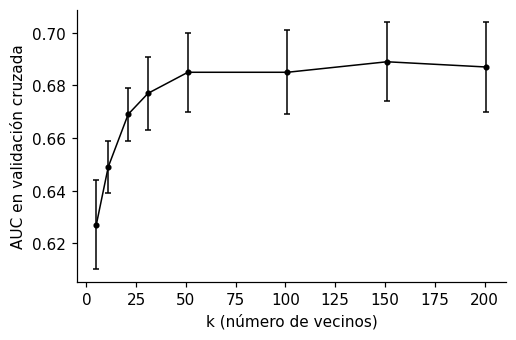

In [20]:
# AUC de KNN según k (para justificar el k elegido)
t_k = pd.DataFrame({"k": K_LISTA, "AUC CV (media)": [aj_P["_auc_k"][k].mean() for k in K_LISTA],
                    "Desv. est.": [aj_P["_auc_k"][k].std() for k in K_LISTA]}).set_index("k").round(3)
display(t_k.T)
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.errorbar(K_LISTA, t_k["AUC CV (media)"], yerr=t_k["Desv. est."], color="black", marker="o", ms=3, lw=1, capsize=2)
ax.set_xlabel("k (número de vecinos)"); ax.set_ylabel("AUC en validación cruzada")
plt.tight_layout(); plt.savefig("salidas/fig_knn_k.png", dpi=200); plt.show()


In [21]:
nombres_mod = NOMBRES_MOD
tabla_cv = pd.DataFrame({
    n: {"ROC-AUC CV (media)": aj_P[n]["cv_media"], "ROC-AUC CV (desv.)": aj_P[n]["cv_std"],
        "PR-AUC CV (media)": aj_P[n]["pr_cv_media"], "PR-AUC CV (desv.)": aj_P[n]["pr_cv_std"],
        "Hiperparámetro elegido": (f"k = {aj_P[n]['params']['k']}" if n == "KNN" else "—")}
    for n in nombres_mod}).T
tabla_cv["ROC-AUC CV (media)"] = tabla_cv["ROC-AUC CV (media)"].astype(float).round(3)
tabla_cv["ROC-AUC CV (desv.)"] = tabla_cv["ROC-AUC CV (desv.)"].astype(float).round(3)
tabla_cv.to_csv("salidas/tabla_cv.csv")
display(tabla_cv)


,ROC-AUC CV (media),ROC-AUC CV (desv.),PR-AUC CV (media),PR-AUC CV (desv.),Hiperparámetro elegido
Regresión logística,0.698,0.017,0.835298,0.013451,—
LDA,0.699,0.017,0.834548,0.013393,—
KNN,0.689,0.015,0.827428,0.005666,k = 151
Naive Bayes,0.657,0.012,0.805696,0.01107,—


## 11. Evaluación final en el conjunto de prueba (correcciones 5 y 6)
Aquí se usa por primera vez el 20 % de prueba, **una sola vez**, con los modelos ya elegidos. Se reporta el AUC como métrica principal y Recall, Precision, F1 y la matriz de confusión como complemento. Cada modelo se compara con la línea base.

**Métricas por umbral (como en clase).** El score de la regresión logística es una probabilidad; la etiqueta depende del umbral \(t\): \(\hat y = 1\) si \(p \ge t\). El **0.5** es convención, no necesariamente el punto de operación óptimo. El **índice de Youden** es \(J = \text{sensibilidad} + \text{especificidad} - 1 = TPR - FPR\). **Maximizar \(J\)** elige el punto de la curva ROC con mayor separación respecto a la diagonal (diapositiva *Selección de modelos*). También se puede elegir \(t\) por costos \(C_{FN}\cdot FN + C_{FP}\cdot FP\); aquí mostramos Youden como criterio neutral de equilibrio entre tipos de error.

El umbral Youden se estima **solo con probabilidades out-of-fold del entrenamiento** (`cross_val_predict`), para no usar el conjunto de prueba en esa decisión. La tabla de abajo ilustra cómo cambian sensibilidad, especificidad y \(J\) al mover \(t\) (misma lógica que el ejemplo del curso con tres umbrales).

Al comparar modelos, la pregunta no es «¿pasó un número fijo?», sino:
1. ¿Cuánto mejora el AUC frente a la línea base (0.5)?
2. ¿Qué tipos de error comete: cuántos morosos deja pasar (FN) y a cuántos buenos pagadores rechaza (FP)?


In [22]:
def metricas_en_umbral(y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    tpr = tp / (tp + fn) if (tp + fn) else 0.0
    tnr = tn / (tn + fp) if (tn + fp) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    j = tpr + tnr - 1  # Youden = TPR - FPR
    return {"Umbral": t, "Sensibilidad (TPR)": tpr, "Especificidad (TNR)": tnr, "J (Youden)": j, "FN": fn, "FP": fp}

def umbral_youden(y_true, proba):
    mejor_u, mejor_v = 0.5, -1.0
    for u in np.linspace(0.05, 0.95, 181):
        m = metricas_en_umbral(y_true, proba, u)
        if m["J (Youden)"] > mejor_v:
            mejor_v, mejor_u = m["J (Youden)"], u
    return mejor_u

# Probabilidades OOF en entrenamiento (regresión logística, escenario B)
_pipe_oof = construir_pipeline(cols_P, LogisticRegression(C=1e6, max_iter=5000))
_proba_oof = cross_val_predict(_pipe_oof, X_tr_full[cols_P], y_tr, cv=cv, method="predict_proba")[:, 1]
UMBRAL_YOUDEN = umbral_youden(y_tr, _proba_oof)

_ejemplo_t = sorted(set([0.30, 0.50, 0.70, round(UMBRAL_YOUDEN, 2)]))
tabla_youden_oof = pd.DataFrame([metricas_en_umbral(y_tr, _proba_oof, t) for t in _ejemplo_t]).set_index("Umbral")
tabla_youden_oof = tabla_youden_oof.round(3)
tabla_youden_oof.to_csv("salidas/tabla_youden_umbrales_oof.csv")
print("Índice de Youden J = sensibilidad + especificidad − 1 (máximo en OOF train → umbral", round(UMBRAL_YOUDEN, 3), ")")
display(tabla_youden_oof)

def evaluar_en_prueba(ajustados, cols):
    filas, probas = {}, {}
    for nombre in NOMBRES_MOD:
        m = ajustados[nombre]["modelo"]
        p = m.predict_proba(X_te_full[cols])[:, 1]
        probas[nombre] = p
        filas[nombre] = evaluar(y_te, p, (p >= 0.5).astype(int))
    filas["Línea base (siempre mora=1)"] = res_base
    # Logística con umbral Youden (OOF)
    p_lr = probas.get("Regresión logística")
    if p_lr is not None:
        filas["Reg. logística (umbral Youden OOF)"] = evaluar(y_te, p_lr, (p_lr >= UMBRAL_YOUDEN).astype(int))
    probas["Línea base (siempre mora=1)"] = p_base
    return pd.DataFrame(filas).T, probas

res_P, probas_P = evaluar_en_prueba(aj_P, cols_P)

# Alternativa: regresión logística con peso de clases (sección 9)
alt = construir_pipeline(cols_P, LogisticRegression(C=1e6, max_iter=5000, class_weight="balanced")).fit(X_tr_full[cols_P], y_tr)
p_alt = alt.predict_proba(X_te_full[cols_P])[:, 1]
res_P.loc["Reg. logística con peso de clases"] = pd.Series(evaluar(y_te, p_alt, (p_alt >= 0.5).astype(int)))

tabla_test = res_P.copy()
for c in ["AUC", "PR-AUC", "Recall (mora=1)", "Precision (mora=1)", "F1 (mora=1)", "Recall (mora=0)", "Accuracy"]:
    tabla_test[c] = tabla_test[c].astype(float).round(3)
for c in ["VP", "FN", "FP", "VN"]:
    tabla_test[c] = tabla_test[c].astype(int)
tabla_test.to_csv("salidas/tabla_test_principal.csv")
display(tabla_test)


Índice de Youden J = sensibilidad + especificidad − 1 (máximo en OOF train → umbral 0.71 )


,Sensibilidad (TPR),Especificidad (TNR),J (Youden),FN,FP
Umbral,,,,,
0.30,0.994,0.041,0.035,22,1351
0.50,0.929,0.236,0.166,244,1076
0.70,0.703,0.590,0.293,1025,578
0.71,0.684,0.614,0.298,1090,544


,AUC,PR-AUC,Recall (mora=1),Precision (mora=1),F1 (mora=1),Recall (mora=0),Accuracy,VP,FN,FP,VN
Regresión logística,0.722,0.840,0.942,0.754,0.838,0.247,0.741,813,50,265,87
LDA,0.719,0.838,0.940,0.759,0.840,0.267,0.745,811,52,258,94
KNN,0.714,0.830,0.961,0.747,0.840,0.202,0.741,829,34,281,71
Naive Bayes,0.685,0.828,0.641,0.814,0.717,0.642,0.641,553,310,126,226
Línea base (siempre mora=1),0.500,0.710,1.000,0.710,0.831,0.000,0.710,863,0,352,0
Reg. logística (umbral Youden OOF),0.722,0.840,0.689,0.822,0.750,0.634,0.673,595,268,129,223
Reg. logística con peso de clases,0.720,0.840,0.683,0.819,0.745,0.631,0.667,589,274,130,222


In [23]:
# Incertidumbre del AUC de prueba: intervalo por bootstrap (remuestreo de los clientes de prueba)
rng = np.random.default_rng(SEED)
yt = y_te.to_numpy()
ic = {}
for nombre in NOMBRES_MOD:
    p = probas_P[nombre]
    aucs = []
    for _ in range(1000):
        idx = rng.integers(0, len(yt), len(yt))
        aucs.append(roc_auc_score(yt[idx], p[idx]))
    ic[nombre] = (np.percentile(aucs, 2.5), np.percentile(aucs, 97.5))
tabla_ic = pd.DataFrame(ic, index=["IC95% inf", "IC95% sup"]).T.round(3)
tabla_ic.to_csv("salidas/tabla_ic_auc.csv")
display(tabla_ic)


,IC95% inf,IC95% sup
Regresión logística,0.689,0.751
LDA,0.685,0.753
KNN,0.679,0.748
Naive Bayes,0.654,0.718


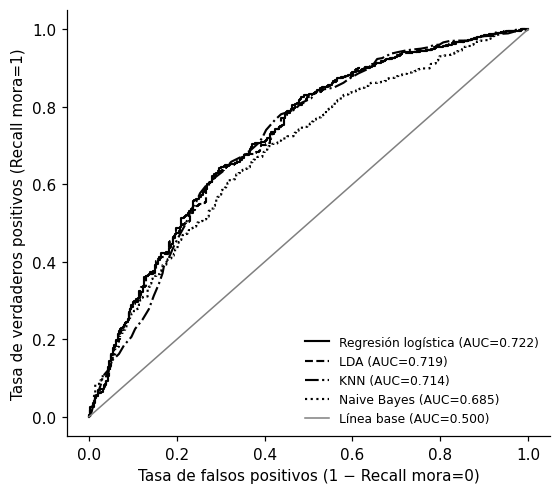

In [24]:
# Curvas ROC
fig, ax = plt.subplots(figsize=(5.2, 4.6))
estilos = ["-", "--", "-.", ":"]
for i, nombre in enumerate(NOMBRES_MOD):
    p = probas_P[nombre]
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, linestyle=estilos[i], color="black", lw=1.4, label=f"{nombre} (AUC={roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1, label="Línea base (AUC=0.500)")
ax.set_xlabel("Tasa de falsos positivos (1 − Recall mora=0)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall mora=1)")
ax.legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("salidas/fig_roc.png", dpi=200)
plt.show()


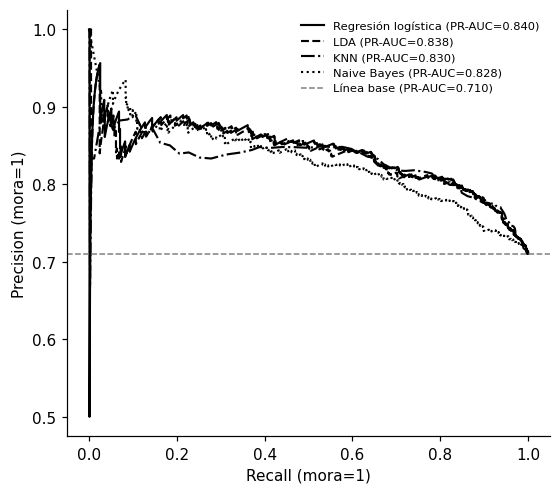

In [25]:
# Curvas precision–recall (complemento al AUC; referencia ≈ prevalencia de mora)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
estilos = ["-", "--", "-.", ":"]
prev = y_te.mean()
for i, nombre in enumerate(NOMBRES_MOD):
    p = probas_P[nombre]
    prec, rec, _ = precision_recall_curve(y_te, p)
    pr_auc = average_precision_score(y_te, p)
    ax.plot(rec, prec, linestyle=estilos[i], color="black", lw=1.4,
            label=f"{nombre} (PR-AUC={pr_auc:.3f})")
ax.axhline(prev, color="gray", lw=1, linestyle="--", label=f"Línea base (PR-AUC={prev:.3f})")
ax.set_xlabel("Recall (mora=1)")
ax.set_ylabel("Precision (mora=1)")
ax.legend(fontsize=7.5, frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig("salidas/fig_pr.png", dpi=200)
plt.show()


In [26]:
# Matrices de confusión: regresión logística y línea base
def mc(y_true, pred):
    return pd.DataFrame(confusion_matrix(y_true, pred, labels=[0, 1]),
                        index=["Real: sin mora", "Real: con mora"], columns=["Pred: sin mora", "Pred: con mora"])
print("Regresión logística")
display(mc(y_te, (probas_P["Regresión logística"] >= 0.5).astype(int)))
print("Línea base")
display(mc(y_te, np.ones(len(y_te), dtype=int)))


Regresión logística


,Pred: sin mora,Pred: con mora
Real: sin mora,87,265
Real: con mora,50,813


Línea base


,Pred: sin mora,Pred: con mora
Real: sin mora,0,352
Real: con mora,0,863


## 12. Análisis de sensibilidad
Dos preguntas: (a) ¿cuánto cambian los resultados al incluir o quitar las variables sospechosas? y (b) ¿cuánto se infla el resultado si no eliminamos los duplicados?

### 12.1 Escenarios de variables
Se repite todo el procedimiento (elección de k solo con entrenamiento, evaluación en prueba) para los tres escenarios.


In [27]:
filas = []
for nom_esc, cols in ESCENARIOS.items():
    aj = ajustar_todos(cols, verbose=False)
    r, _ = evaluar_en_prueba(aj, cols)
    for modelo in NOMBRES_MOD:
        filas.append({"Escenario": nom_esc, "Modelo": modelo, "AUC CV": aj[modelo]["cv_media"], "AUC prueba": r.loc[modelo, "AUC"]})
sens = pd.DataFrame(filas)
orden = list(ESCENARIOS.keys())
piv = sens.pivot(index="Modelo", columns="Escenario", values="AUC prueba").round(3)[orden].loc[NOMBRES_MOD]
piv.to_csv("salidas/tabla_sensibilidad_variables.csv")
display(piv)
pivcv = sens.pivot(index="Modelo", columns="Escenario", values="AUC CV").round(3)[orden].loc[NOMBRES_MOD]
print("AUC en validación cruzada:")
display(pivcv)


Escenario,A. Completo (13 variables),B. Principal (sin atraso ni clasif_sbs),"C. Conservador (sin atraso, clasif_sbs ni score)"
Modelo,,,
Regresión logística,0.734,0.722,0.709
LDA,0.730,0.719,0.707
KNN,0.721,0.714,0.702
Naive Bayes,0.692,0.685,0.677


AUC en validación cruzada:


Escenario,A. Completo (13 variables),B. Principal (sin atraso ni clasif_sbs),"C. Conservador (sin atraso, clasif_sbs ni score)"
Modelo,,,
Regresión logística,0.715,0.698,0.692
LDA,0.715,0.699,0.693
KNN,0.703,0.689,0.681
Naive Bayes,0.662,0.657,0.651


**Cómo leerlo.** Si el escenario A (con `atraso` y `clasif_sbs`) diera un AUC mucho más alto que el B, sería señal de que esas variables «saben» la respuesta. Si A y B dan casi lo mismo, quitarlas casi no cuesta capacidad predictiva y es la opción más segura. El escenario C muestra qué parte del resultado depende del `score`.

### 12.2 ¿Qué pasa si no eliminamos los duplicados?
Hacemos una partición aleatoria sobre la base **original** (con copias) y miramos el AUC de prueba de la regresión logística y de KNN, con tres semillas distintas.


In [28]:
def auc_prueba(datos, semilla, modelo):
    """AUC de prueba con una partición aleatoria estratificada de 'datos'."""
    Xd, yd = datos.drop(columns="mora"), datos["mora"]
    Xa, Xb, ya, yb = train_test_split(Xd, yd, test_size=0.20, stratify=yd, random_state=semilla)
    pipe = construir_pipeline(cols_P, modelo).fit(Xa[cols_P], ya)
    return roc_auc_score(yb, pipe.predict_proba(Xb[cols_P])[:, 1])

filas = []
for semilla in [42, 1, 2]:
    for etiqueta, datos in [("Con duplicados", df_raw), ("Sin duplicados", df)]:
        filas.append({"Base": etiqueta, "Semilla": semilla,
                      "Regresión logística": auc_prueba(datos, semilla, LogisticRegression(C=1e6, max_iter=5000)),
                      "KNN (k=5)": auc_prueba(datos, semilla, KNeighborsClassifier(5))})
dup_tab = pd.DataFrame(filas).groupby("Base")[["Regresión logística", "KNN (k=5)"]].mean().round(3)
dup_tab.to_csv("salidas/tabla_duplicados.csv")
display(dup_tab)

Xa, Xb, ya, yb = train_test_split(df_raw.drop(columns="mora"), df_raw["mora"], test_size=0.20, stratify=df_raw["mora"], random_state=SEED)
claves_tr = set(map(tuple, Xa.assign(mora=ya).fillna(-999).to_numpy()))
copias = np.mean([tuple(r) in claves_tr for r in Xb.assign(mora=yb).fillna(-999).to_numpy()])
print(f"% de filas de prueba con una copia exacta en entrenamiento (base con duplicados): {100*copias:.1f}%")


,Regresión logística,KNN (k=5)
Base,,
Con duplicados,0.710,0.732
Sin duplicados,0.715,0.652


% de filas de prueba con una copia exacta en entrenamiento (base con duplicados): 41.9%


**Lectura.** Con duplicados, cerca del 40 % de las filas de prueba ya fue vista en entrenamiento. El efecto depende del modelo: en la regresión logística, que no memoriza filas, el AUC casi no cambia; en KNN, que sí se apoya en filas idénticas, el AUC **sube bastante** y sería engañoso. Es una fuga de datos silenciosa, y confirma la decisión de eliminar duplicados antes de dividir. (Las filas de prueba son distintas en cada base, por eso solo comparamos el patrón y promediamos tres particiones.)


## 13. Interpretación del modelo (sin hablar de causas)
Usamos la regresión logística del escenario principal. Los coeficientes se calculan sobre variables numéricas estandarizadas, así que se pueden comparar entre sí. El coeficiente indica **asociación** con la probabilidad de mora en esta base, **no un efecto causal**: por ejemplo, que `nivel_educ` esté asociado a mora no significa que estudiar menos cause mora, porque educación, ingreso y empleo van juntos.

`odds ratio` = cuánto se multiplican las probabilidades relativas de mora (mora frente a no mora) al subir una desviación estándar la variable, dejando las demás fijas. En las categóricas, es frente a la categoría de referencia (la primera en orden alfabético: `vivienda` = ALQUILADA, `nivel_educ` = SECUNDARIA). Las zonas no se interpretan porque son muchas y varias tienen pocos clientes.


In [29]:
m = aj_P["Regresión logística"]["modelo"]
nombres = m.named_steps["prep"].get_feature_names_out()
coef = pd.Series(m.named_steps["modelo"].coef_[0], index=nombres)
coef.index = [n.replace("num__", "").replace("cat__", "").replace("missingindicator_", "falta_").replace("infrequent_sklearn", "SIN EDUCACION (poco frecuente)") for n in coef.index]

tabla_coef = pd.DataFrame({"coeficiente": coef, "odds ratio": np.exp(coef)})
no_zona = tabla_coef[~tabla_coef.index.str.startswith("zona_")]
no_zona = no_zona.reindex(no_zona["coeficiente"].abs().sort_values(ascending=False).index).round(3)
no_zona.to_csv("salidas/tabla_coeficientes.csv")
display(no_zona)


,coeficiente,odds ratio
nivel_educ_UNIVERSITARIA,-0.487,0.615
exp_sf,-0.309,0.734
score,-0.293,0.746
nivel_ahorro,-0.290,0.748
nivel_educ_TECNICA,-0.238,0.788
nivel_educ_SIN EDUCACION (poco frecuente),0.136,1.145
deuda_sf,0.135,1.145
vivienda_PROPIA,0.131,1.140
falta_deuda_sf,-0.103,0.902
linea_sf,-0.100,0.905


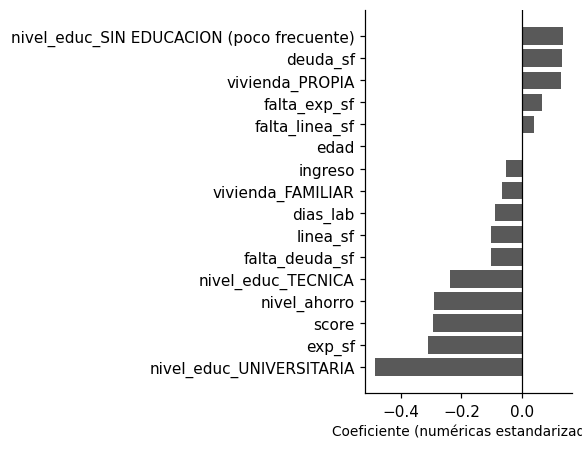

In [30]:
d = no_zona["coeficiente"].sort_values()
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.barh(d.index, d.values, color="0.35")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente (numéricas estandarizadas)", fontsize=9)
plt.tight_layout()
plt.savefig("salidas/fig_coeficientes.png", dpi=200)
plt.show()


**Cómo leer los signos.** Un coeficiente positivo significa que, en esta base, valores más altos de la variable (o pertenecer a esa categoría frente a la de referencia) van acompañados de mayor probabilidad de mora; negativo, de menor probabilidad. Solo describimos asociaciones. Las variables con coeficientes grandes son las que más ayudan al modelo a ordenar clientes por riesgo, y eso no equivale a decir que «causan» la mora.


## 14. Conclusiones, limitaciones y lista de chequeo de la rúbrica
**Conclusiones** (los números concretos están en las tablas de arriba y en el informe):
- Con información financiera y socioeconómica disponible previamente, los modelos **superan claramente a la línea base** en AUC, pero el nivel alcanzado es **moderado** (lejos del 85 % del artículo). El riesgo de mora se puede ordenar mejor que al azar, pero no predecir con alta precisión.
- La regresión logística, **LDA** y KNN rinden de forma parecida; las diferencias son menores que la variabilidad de la validación cruzada, así que no podemos coronar un único ganador. No hay evidencia de que un modelo más complejo ayude con estas variables.
- Naive Bayes es claramente el peor. Es coherente con lo que dijimos en la primera entrega: sus variables no son independientes, y suponer que lo son tiene un costo medible.
- Quitar `atraso` y `clasif_sbs` cuesta poca capacidad predictiva, así que el escenario principal es más seguro sin perder mucho (sección 12).
- Los tipos de error dependen del punto de corte: con corte 0.5 la regresión logística detecta a casi todos los morosos pero rechaza a muchos buenos pagadores; el umbral **Youden** estimado con predicciones OOF en entrenamiento (~0.71) equilibra mejor sensibilidad y especificidad en prueba; con peso de clases pasa lo contrario. La elección depende del costo de cada error para el banco.

**Limitaciones.**
- No hay diccionario de datos: la definición de `mora` y el momento en que se midió cada variable son supuestos nuestros.
- La base tiene 71 % de morosos, muy por encima de la morosidad real del Perú (entre 4 % y 11 % según la SBS). Las probabilidades que da el modelo **no** son probabilidades reales de mora en la población; sirven para ordenar clientes.
- No hay identificador de cliente ni fecha: no pudimos comprobar que los duplicados sean el mismo cliente ni validar el modelo en otro periodo.
- Los coeficientes muestran asociación, no causalidad.

**Lista de chequeo frente a la rúbrica de la Segunda entrega**

| Criterio | Dónde se cumple |
|---|---|
| Consolidación de los datos | Secciones 2 a 4: definición de `mora`, auditoría de variables, duplicados y faltantes |
| Flujo sin fuga de datos | Secciones 5, 7 y 8: partición estratificada, pipeline, balanceo dentro del pipeline y cuatro pruebas de fuga |
| Entrenamiento y comparación | Secciones 6, 9 y 10: línea base, logística + LDA + KNN + Naive Bayes (contraste), k de KNN por validación cruzada |
| Validación, métricas e interpretación | Secciones 11 a 13: ROC-AUC, **PR-AUC**, Recall, Precision, F1, umbral Youden (OOF), matriz de confusión, bootstrap, sensibilidad y coeficientes |
| Comunicación e informe | Informe en LaTeX con tablas y figuras numeradas; este notebook como código reproducible |

**Chequeo actualizado:** LDA incorporado; Naive Bayes como contraste; PR-AUC en balanceo y modelos; tabla de umbrales con \(J\) (Youden) en OOF + umbral operativo; escenario B sin `atraso`/`clasif_sbs`; línea base; feedback de mora, fuga y logit.
